# W9-C: selector diagnostic at K_E=2

**Diagnostic only.** The completed W9-B primary decision is K_E=0 (keep the saved draft). This separately authorized FIT experiment compares selectors at a fixed positive budget K_E=2. It does not replace that primary decision or establish a benefit from always adding evidence.

Configuration: `configs/week9/w9c_k2_diagnostic.yaml`. Outputs: `results/week9/diagnostics/w9c_k2/selection/fit/`. Frozen W9-A retrieval, canonical context, raw evidence and FP16 efficient attention stay fixed. Default execution flags are disabled; manually enable the full run after reviewing setup.


In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'src/week9').is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Open this notebook within CS787-RAG-Project')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.week9.config import load_config, load_frozen
from src.week9.runner import rows_path, phase_dir, load_phase
RUN_FULL = True
RUN_SMOKE = False
FREEZE_FIT = False
SMOKE_LIMIT = 2
SPLIT = 'fit'
assert SPLIT in ('fit', 'internal_val', 'dev')
PHASE = 'c'
CONFIG = ROOT / 'configs/week9/w9c_k2_diagnostic.yaml'
SCRIPT = ROOT / 'scripts/week9/run_w9c_selection.py'
cfg = load_config(CONFIG)


In [2]:
# Validate frozen prerequisites before loading a GPU model.
from src.week9.runner import dependencies
if RUN_FULL or RUN_SMOKE:
    b_freeze = ROOT / cfg['output_root'] / 'frozen/w9b_frozen_config.json'
    if not b_freeze.is_file():
        raise FileNotFoundError(
            'W9-B results must be reviewed and frozen before W9-C. '
            'The completed FIT surface currently proposes K_E=0. '
            'Do not silently replace that decision with a positive budget.')
    prerequisites = dependencies(cfg, PHASE, SPLIT)
    if prerequisites['b']['settings']['evidence_k'] == 0:
        raise ValueError(
            'Frozen K_E=0 makes every selector return the same saved draft. '
            'Skip the redundant selector experiment, or explicitly configure '
            'a separate positive-budget diagnostic with separate artifacts.')
    assert cfg.get('diagnostic_only') is True
    assert prerequisites['b'].get('diagnostic_only') is True
    assert prerequisites['b']['settings']['evidence_k'] == 2
    assert prerequisites['b']['analysis_role'] == 'fit_diagnostic_fixed_k'
    if FREEZE_FIT:
        raise ValueError('Keep FREEZE_FIT=False: this diagnostic does not freeze a primary selector decision.')
    print('DIAGNOSTIC ONLY: K_E=2; primary W9-B remains K_E=0.')
else:
    print('Execution disabled. W9-C requires a reviewed frozen W9-B budget.')


DIAGNOSTIC ONLY: K_E=2; primary W9-B remains K_E=0.


In [3]:
command = [str(ROOT / 'sara_env/bin/python'), str(SCRIPT), '--split', SPLIT,
           '--config', str(CONFIG), '--resume']
if RUN_FULL:
    if FREEZE_FIT:
        assert SPLIT == 'fit'
        command.append('--freeze')
    if PHASE == 'g':
        command.append('--collect-headroom-oof')
    subprocess.run(command, cwd=ROOT, check=True)
else:
    print('Full experiment disabled. Set RUN_FULL=True explicitly.')
if RUN_SMOKE:
    subprocess.run(command + ['--smoke-limit', str(SMOKE_LIMIT)], cwd=ROOT, check=True)


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [00:01<00:00,  2.31it/s]
Some weights of XMistralForCausalLM were not initialized from the model checkpoint at mistralai/Mistral-7B-Instruct-v0.2 and are newly initialized: ['projector.projector.0.bias', 'projector.projector.0.weight', 'projector.projector.2.bias', 'projector.projector.2.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `m

W9-C: 8730 saved real rows; complete=True; artifacts=/home/gunavenkat/Downloads/CS787-RAG-Project/results/week9/diagnostics/w9c_k2/selection/fit


In [4]:
directory = phase_dir(cfg, PHASE, SPLIT)
path = rows_path(cfg, PHASE, SPLIT)
if path.is_file():
    rows = load_phase(cfg, PHASE, SPLIT)
    run_manifest = json.loads((directory / f'w9{PHASE}_manifest.json').read_text())
    from src.week9.provenance import digest
    expected_config = dict(cfg, _seed=run_manifest['seed'])
    if digest(expected_config) != run_manifest['config_hash']:
        raise ValueError('Notebook configuration differs from the saved run')
    print('Complete:', run_manifest['complete'], 'Rows:', len(rows))
    print('Input/source fingerprints validated by load_phase.')
    frame = pd.DataFrame(rows)
    display(frame[[c for c in ['question_id','paper_id','policy','representation','retriever',
        'retrieval_width','evidence_k','f1','total_query_prompt_tokens'] if c in frame]].head(12))
    for table in sorted(directory.glob('*.csv')):
        print(table.name)
        display(pd.read_csv(table).head(30))
else:
    print('No full-run artifacts yet. Run the phase manually; no fallback metrics were created.')


Complete: True Rows: 8730
Input/source fingerprints validated by load_phase.


,question_id,paper_id,policy,retrieval_width,evidence_k,f1,total_query_prompt_tokens
0,512,139,BM25,20,2,0.900000,4110
1,512,139,QuerySemantic,20,2,0.705882,4110
2,512,139,DraftSemantic,20,2,0.705882,4110
3,512,139,QueryDraft,20,2,0.705882,4110
4,512,139,SANE-adapted,20,2,0.705882,4759
5,513,139,BM25,20,2,0.500000,3804
6,513,139,QuerySemantic,20,2,0.320000,3898
7,513,139,DraftSemantic,20,2,0.500000,3884
8,513,139,QueryDraft,20,2,0.320000,3884
9,513,139,SANE-adapted,20,2,0.320000,4410


w9c_summary.csv


,policy,n_queries,f1,mean_selected_delta_f1,help_selected_rate,hurt_selected_rate,exact_match,help,hurt,answer_changed,...,num_lm_calls,retrieval_query_time,selection_latency,extraction_latency,revision_latency,measured_end_to_end_latency,extraction_rate,promotion_rate,faithfulness,complexity
0,BM25,1746,0.382157,-0.003474,0.325888,0.280641,0.190722,0.325888,0.280641,0.774341,...,2.0,0.00496,0.002008,NaN,2.247690,NaN,0.0,1.0,1.0,0
1,QuerySemantic,1746,0.383490,-0.002141,0.324742,0.278923,0.192440,0.324742,0.278923,0.770332,...,2.0,0.00496,0.293242,NaN,2.233333,NaN,0.0,1.0,1.0,1
2,DraftSemantic,1746,0.385004,-0.000627,0.321306,0.281787,0.193013,0.321306,0.281787,0.762887,...,2.0,0.00496,0.292409,NaN,2.255731,NaN,0.0,1.0,1.0,2
3,QueryDraft,1746,0.384095,-0.001536,0.324170,0.285223,0.193585,0.324170,0.285223,0.770332,...,2.0,0.00496,0.291857,NaN,2.257339,NaN,0.0,1.0,1.0,3
4,SANE-adapted,1746,0.386336,0.000705,0.331042,0.274341,0.190722,0.331042,0.274341,0.768041,...,3.0,0.00496,0.419180,NaN,2.256331,NaN,0.0,1.0,1.0,4


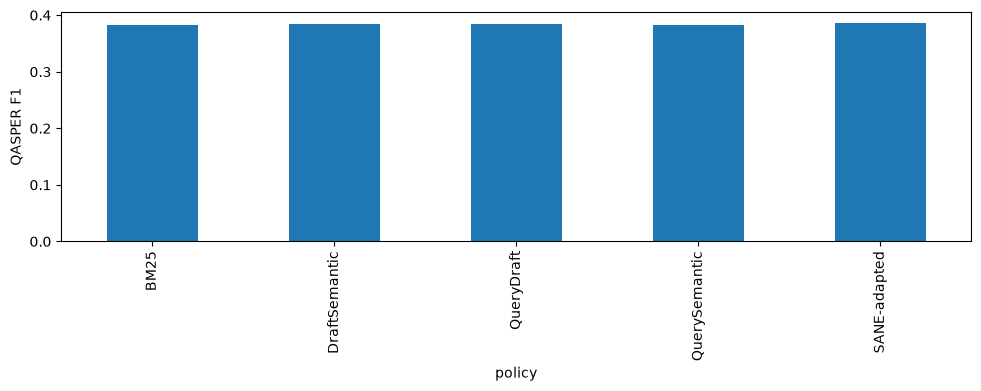

In [5]:
if path.is_file():
    import matplotlib.pyplot as plt
    if PHASE == 'a':
        table = pd.read_csv(directory / 'w9a_summary.csv')
        display(table.pivot_table(index=['representation','retriever'], columns='retrieval_width',
                                 values='all_gold_evidence_recall'))
        ax = table.pivot_table(index='representation', columns='retriever',
                              values='all_gold_evidence_recall').plot.bar(figsize=(12,5))
        ax.set_ylabel('All annotated evidence recall (paragraph proxy)')
    elif 'f1' in frame:
        group = 'evidence_k' if PHASE == 'b' else 'policy'
        ax = frame.groupby(group).f1.mean().plot.bar(figsize=(10,4))
        ax.set_ylabel('QASPER F1')
    else:
        ax = None
    if ax is not None:
        (directory / 'figures').mkdir(exist_ok=True)
        ax.figure.tight_layout()
        ax.figure.savefig(directory / 'figures' / f'w9{PHASE}_overview.png', dpi=160)
        plt.show()


## Manual decision checkpoint

Inspect completeness, source/config fingerprints, paired paper-bootstrap intervals and total query-time token costs before freezing. A smoke run cannot freeze a configuration. Summary tables come only from saved real rows. Exact-span support is separate from fact entailment, which is unmeasured unless explicitly judged. No next phase is launched here.

To regenerate summaries without loading the generator, run this phase script with `--analyze-only --resume`. Add `--freeze` only after a complete FIT run. H requires verified outer paper-fold outcomes and `--collect-oof`; see the runbook. Changes to source/config/model fingerprints require a new output root; incompatible caches are refused.
